# E-Commerce Customer Segmentation using RFM, K-Means and DBSCAN

**Case Study 3**

This notebook performs customer segmentation on the UCI Online Retail dataset using:
- RFM feature engineering (Recency, Frequency and Monetary)
- Data cleaning, outlier capping, log transformation and robust scaling
- K-Means clustering with Elbow and Silhouette analysis
- DBSCAN clustering with parameter exploration
- PCA and t-SNE visualizations
- Customer persona generation and marketing recommendations

> **Important:** Clustering is an unsupervised learning task. There is no target label, so conventional training accuracy is not applicable. We evaluate cluster structure using Silhouette Score and Davies–Bouldin Index, alongside business interpretability.

## 1. Install and import libraries

In [1]:
!pip -q install openpyxl scikit-learn seaborn

In [2]:
import os
import zipfile
import requests
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Download and load the dataset
The notebook downloads the UCI Online Retail Excel dataset directly. An internet connection is required.

In [3]:
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
zip_path = "online_retail.zip"
extract_dir = "online_retail_data"

response = requests.get(url, timeout=60)
response.raise_for_status()

with open(zip_path, "wb") as file:
    file.write(response.content)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_dir)

excel_files = [
    os.path.join(root, filename)
    for root, _, filenames in os.walk(extract_dir)
    for filename in filenames
    if filename.lower().endswith(".xlsx")
]

if not excel_files:
    raise FileNotFoundError("No Excel file was found in the downloaded dataset.")

df = pd.read_excel(excel_files[0])

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Explore the dataset

In [4]:
print("Dataset information:")
df.info()

print("\\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

print("\\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\\nUnique customers:", df["CustomerID"].nunique())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
\nMissing values:


,Missing values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


\nDescriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nUnique customers: 4372


## 4. Clean and prepare transaction data
Remove rows without customer IDs, cancelled invoices, non-positive quantities and invalid prices. These exclusions mean the Monetary value below reflects positive purchases rather than net revenue after returns.

In [5]:
required_columns = [
    "InvoiceNo", "StockCode", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

df = df.dropna(subset=["CustomerID"]).copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

# Remove cancelled invoices
df = df[~df["InvoiceNo"].str.startswith("C")].copy()

# Keep valid positive purchases
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned transaction shape:", df.shape)
print("Customers remaining:", df["CustomerID"].nunique())
display(df.head())

Cleaned transaction shape: (397884, 9)
Customers remaining: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 5. Calculate RFM metrics
- **Recency:** Days since the customer's most recent purchase.
- **Frequency:** Number of distinct invoices/purchases.
- **Monetary:** Total positive purchase value.

In [6]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (reference_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
)

rfm = rfm.replace([np.inf, -np.inf], np.nan).dropna()
rfm = rfm[(rfm > 0).all(axis=1)].copy()

print("RFM dataset shape:", rfm.shape)
display(rfm.head())
display(rfm.describe().T)

RFM dataset shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,92.536422,100.014169,1.00,18.000,51.000,142.00,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.000,2.000,5.00,209.00
Monetary,4338.0,2054.266460,8989.230441,3.75,307.415,674.485,1661.74,280206.02


## 6. Explore RFM distributions

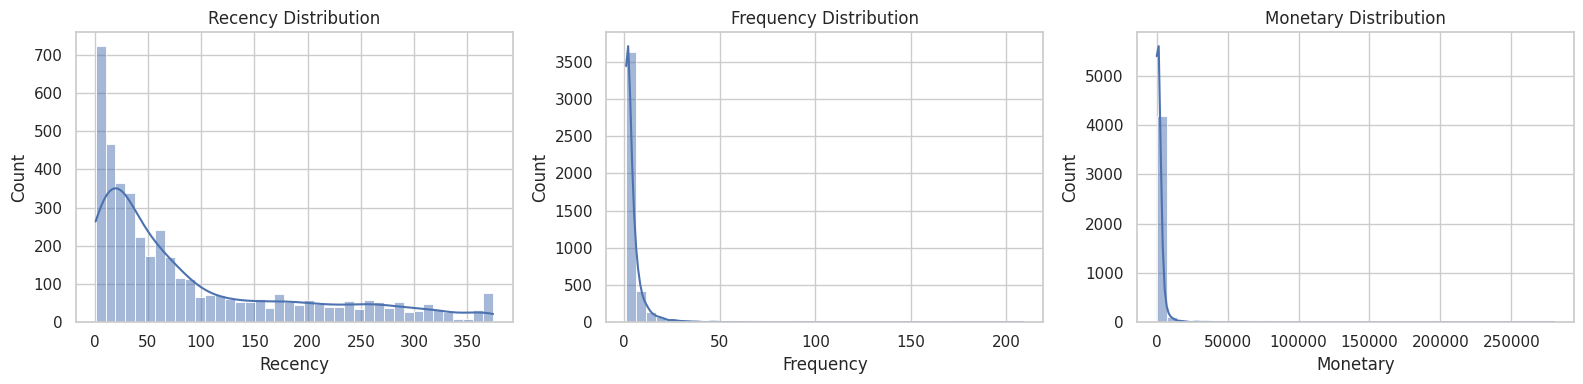

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for axis, column in zip(axes, rfm.columns):
    sns.histplot(rfm[column], bins=40, kde=True, ax=axis)
    axis.set_title(f"{column} Distribution")

plt.tight_layout()
plt.show()

## 7. Handle outliers, transform and scale features
Cap each feature at its 99th percentile to reduce the influence of extreme observations. Apply `log1p` to reduce skewness, then RobustScaler to scale using robust statistics.

In [8]:
rfm_model = rfm.copy()

for column in ["Recency", "Frequency", "Monetary"]:
    upper_limit = rfm_model[column].quantile(0.99)
    rfm_model[column] = rfm_model[column].clip(upper=upper_limit)

rfm_log = np.log1p(rfm_model)

scaler = RobustScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("Transformed and scaled data shape:", rfm_scaled.shape)

Transformed and scaled data shape: (4338, 3)


## 8. PCA dimensionality reduction
PCA converts the three scaled RFM features into two principal components for a compact visualization. Clustering below is performed on the scaled RFM features, not on the 2D PCA projection.

Explained variance by component: [0.75084326 0.19105617]
Total variance explained by 2 components: 94.19%


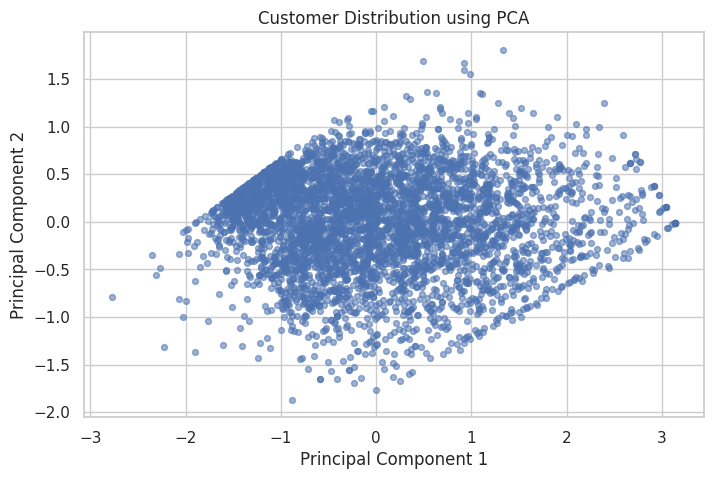

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_data = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"],
    index=rfm.index
)

explained = pca.explained_variance_ratio_
print("Explained variance by component:", explained)
print(f"Total variance explained by 2 components: {explained.sum() * 100:.2f}%")

plt.figure(figsize=(8, 5))
plt.scatter(pca_df["PC1"], pca_df["PC2"], alpha=0.55, s=18)
plt.title("Customer Distribution using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

## 9. Select K for K-Means
Use the Elbow Method and Silhouette Score over a small range of candidate cluster counts. Silhouette is calculated on a reproducible sample for speed.

K=2: silhouette=0.4237
K=3: silhouette=0.3216
K=4: silhouette=0.3301
K=5: silhouette=0.3150
K=6: silhouette=0.3126
K=7: silhouette=0.3056
K=8: silhouette=0.2807


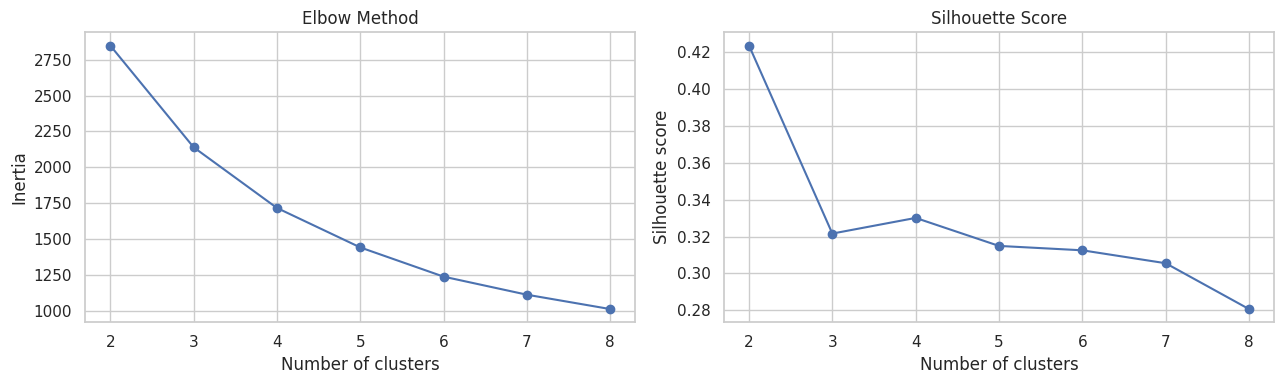

K selected by highest tested silhouette score: 2


In [10]:
k_values = range(2, 9)
inertias = []
kmeans_silhouette_scores = []

sample_size = min(2000, len(rfm_scaled))

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    labels = model.fit_predict(rfm_scaled)

    inertias.append(model.inertia_)
    score = silhouette_score(
        rfm_scaled,
        labels,
        sample_size=sample_size,
        random_state=RANDOM_STATE
    )
    kmeans_silhouette_scores.append(score)
    print(f"K={k}: silhouette={score:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), kmeans_silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

optimal_k = list(k_values)[int(np.argmax(kmeans_silhouette_scores))]
print("K selected by highest tested silhouette score:", optimal_k)

## 10. Fit K-Means and evaluate

In [11]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=RANDOM_STATE,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(rfm_scaled)

kmeans_silhouette = silhouette_score(
    rfm_scaled,
    rfm["KMeans_Cluster"],
    sample_size=min(2000, len(rfm_scaled)),
    random_state=RANDOM_STATE
)
kmeans_db = davies_bouldin_score(rfm_scaled, rfm["KMeans_Cluster"])

print("K-Means Silhouette Score:", round(kmeans_silhouette, 4))
print("K-Means Davies-Bouldin Index:", round(kmeans_db, 4))
print("\\nCluster counts:")
display(rfm["KMeans_Cluster"].value_counts().sort_index().to_frame("Customers"))

K-Means Silhouette Score: 0.4237
K-Means Davies-Bouldin Index: 0.8914
\nCluster counts:


,Customers
KMeans_Cluster,
0,1733
1,2605


## 11. Visualize K-Means clusters using PCA

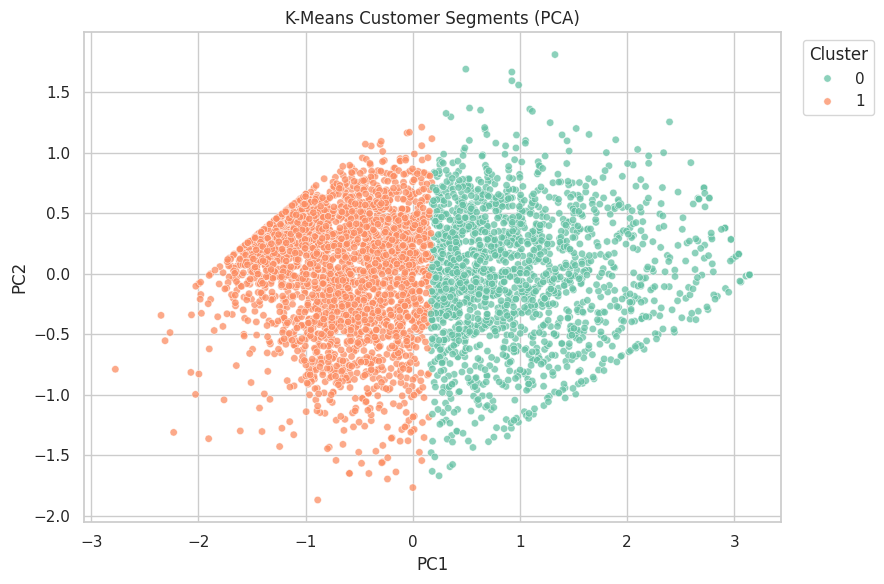

In [12]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue=rfm["KMeans_Cluster"].astype(str),
    palette="Set2",
    s=28,
    alpha=0.75
)
plt.title("K-Means Customer Segments (PCA)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 12. Prepare DBSCAN parameter exploration
DBSCAN groups dense regions and marks isolated observations as noise (`-1`). The k-distance graph helps choose plausible epsilon values. DBSCAN is sensitive to scaling and parameter choice.

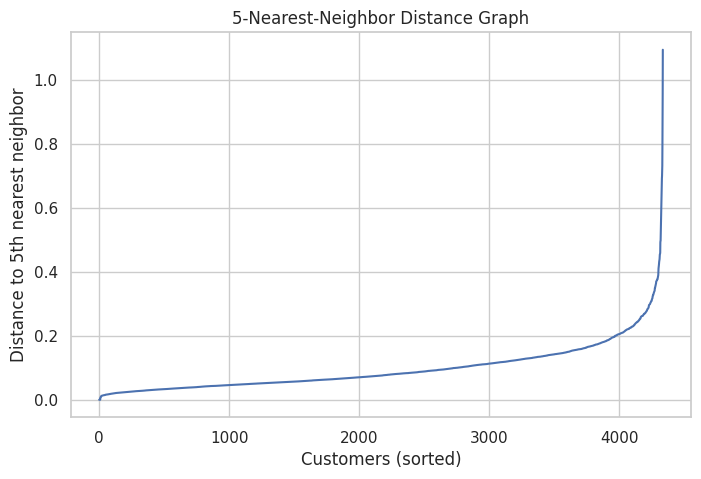

Epsilon candidates: [0.15746173 0.18429628 0.23539291 0.30920175]


In [13]:
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(rfm_scaled)
distances, _ = neighbors.kneighbors(rfm_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.title(f"{min_samples}-Nearest-Neighbor Distance Graph")
plt.xlabel("Customers (sorted)")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.show()

# Test several data-driven epsilon candidates from the distance distribution
eps_values = np.unique(np.quantile(k_distances, [0.85, 0.90, 0.95, 0.98]))
print("Epsilon candidates:", eps_values)

## 13. Fit and tune DBSCAN
Choose the tested epsilon with the highest silhouette score among solutions that produce at least two non-noise clusters and do not label more than 70% of customers as noise. If none qualifies, retain the largest tested epsilon and report the outcome honestly.

In [14]:
best_dbscan_score = -1
best_eps = None
best_labels = None
dbscan_trials = []

for eps in eps_values:
    model = DBSCAN(eps=float(eps), min_samples=min_samples)
    labels = model.fit_predict(rfm_scaled)

    non_noise_mask = labels != -1
    non_noise_labels = labels[non_noise_mask]
    n_clusters = len(set(non_noise_labels))
    noise_ratio = 1 - non_noise_mask.mean()

    score = np.nan
    if n_clusters >= 2 and non_noise_mask.sum() > n_clusters and noise_ratio <= 0.70:
        score = silhouette_score(
            rfm_scaled[non_noise_mask],
            non_noise_labels,
            sample_size=min(2000, non_noise_mask.sum()),
            random_state=RANDOM_STATE
        )

    dbscan_trials.append({
        "eps": float(eps),
        "clusters": n_clusters,
        "noise_ratio": noise_ratio,
        "silhouette": score
    })

    print(
        f"eps={eps:.5f} | clusters={n_clusters} | "
        f"noise={noise_ratio:.1%} | silhouette={score}"
    )

    if not np.isnan(score) and score > best_dbscan_score:
        best_dbscan_score = score
        best_eps = float(eps)
        best_labels = labels

if best_labels is None:
    best_eps = float(eps_values[-1])
    fallback_model = DBSCAN(eps=best_eps, min_samples=min_samples)
    best_labels = fallback_model.fit_predict(rfm_scaled)
    print("\\nNo candidate met the selection criteria. Using the largest tested epsilon.")
else:
    print(f"\\nSelected epsilon: {best_eps:.5f}")

rfm["DBSCAN_Cluster"] = best_labels
display(pd.DataFrame(dbscan_trials))
print("\\nDBSCAN cluster counts:")
display(rfm["DBSCAN_Cluster"].value_counts().sort_index().to_frame("Customers"))

eps=0.15746 | clusters=20 | noise=9.8% | silhouette=0.028647585484461786
eps=0.18430 | clusters=16 | noise=6.0% | silhouette=-0.000102365241480603
eps=0.23539 | clusters=5 | noise=2.7% | silhouette=0.09282955591216545
eps=0.30920 | clusters=3 | noise=0.9% | silhouette=0.184913315357206
\nSelected epsilon: 0.30920


,eps,clusters,noise_ratio,silhouette
0,0.157462,20,0.097971,0.028648
1,0.184296,16,0.059935,-0.000102
2,0.235393,5,0.027432,0.092830
3,0.309202,3,0.008760,0.184913


\nDBSCAN cluster counts:


,Customers
DBSCAN_Cluster,
-1,38
0,2818
1,1478
2,4


## 14. Evaluate DBSCAN
Noise points are excluded from the two cluster-quality metrics because `-1` represents unassigned noise, not a regular customer segment.

In [15]:
dbscan_mask = rfm["DBSCAN_Cluster"].to_numpy() != -1
dbscan_cluster_labels = rfm.loc[dbscan_mask, "DBSCAN_Cluster"].to_numpy()
n_dbscan_clusters = len(set(dbscan_cluster_labels))

dbscan_silhouette = np.nan
dbscan_db = np.nan

if n_dbscan_clusters >= 2 and dbscan_mask.sum() > n_dbscan_clusters:
    dbscan_silhouette = silhouette_score(
        rfm_scaled[dbscan_mask],
        dbscan_cluster_labels,
        sample_size=min(2000, dbscan_mask.sum()),
        random_state=RANDOM_STATE
    )
    dbscan_db = davies_bouldin_score(
        rfm_scaled[dbscan_mask],
        dbscan_cluster_labels
    )
    print("DBSCAN Silhouette Score (non-noise only):", round(dbscan_silhouette, 4))
    print("DBSCAN Davies-Bouldin Index (non-noise only):", round(dbscan_db, 4))
else:
    print("DBSCAN did not produce at least two non-noise clusters; these metrics are not defined.")

print("Noise customers:", int((~dbscan_mask).sum()))
print(f"Noise percentage: {(~dbscan_mask).mean() * 100:.2f}%")

DBSCAN Silhouette Score (non-noise only): 0.1849
DBSCAN Davies-Bouldin Index (non-noise only): 0.9668
Noise customers: 38
Noise percentage: 0.88%


## 15. Visualize DBSCAN clusters using PCA

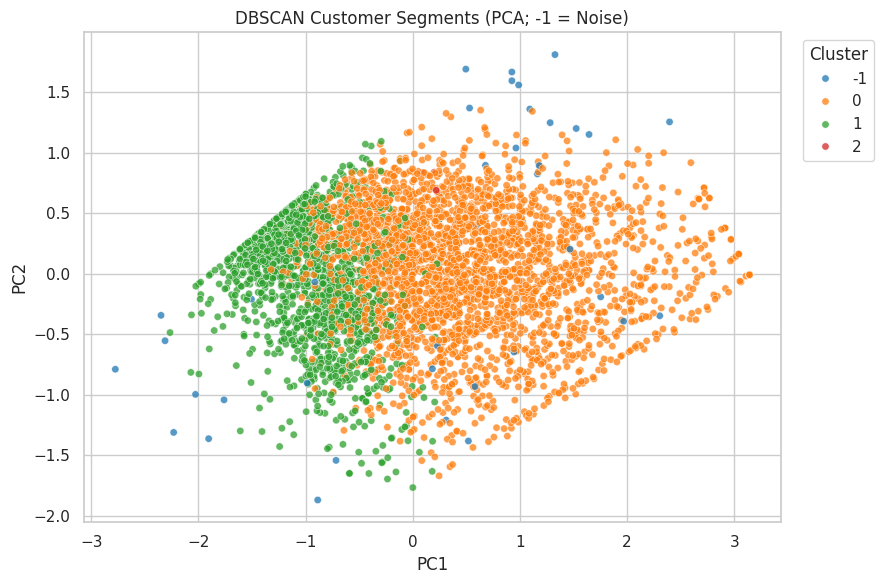

In [16]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=pca_df["PC1"],
    y=pca_df["PC2"],
    hue=rfm["DBSCAN_Cluster"].astype(str),
    palette="tab10",
    s=28,
    alpha=0.75
)
plt.title("DBSCAN Customer Segments (PCA; -1 = Noise)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 16. Visualize customer segments using t-SNE
t-SNE is used only for visualization. It does not create the clusters. The embedding can take longer than PCA, but the Online Retail customer-level RFM dataset is generally manageable in Colab.

In [17]:
perplexity = min(30, max(2, (len(rfm_scaled) - 1) // 3))

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto"
)

tsne_data = tsne.fit_transform(rfm_scaled)

tsne_df = pd.DataFrame(
    tsne_data,
    columns=["TSNE1", "TSNE2"],
    index=rfm.index
)

print("t-SNE completed. Perplexity:", perplexity)

t-SNE completed. Perplexity: 30


### K-Means clusters on t-SNE

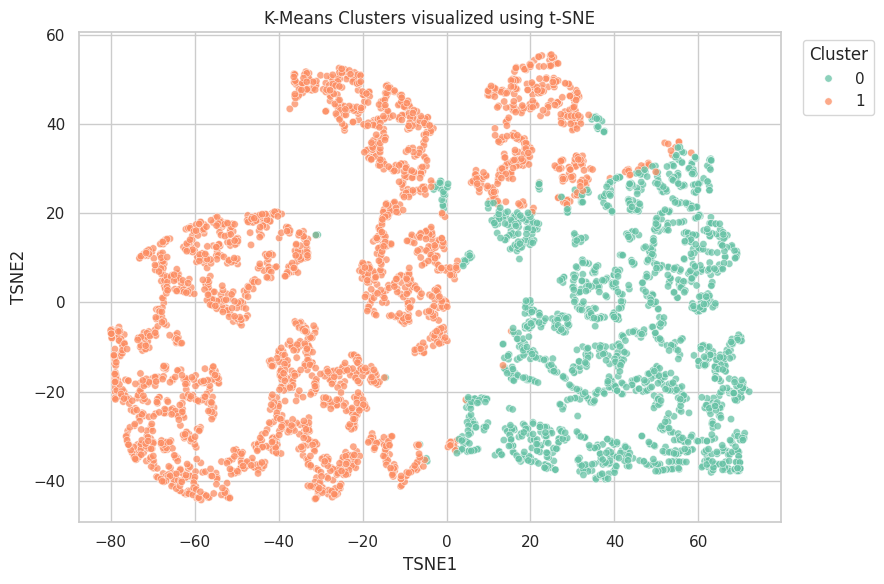

In [18]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=tsne_df["TSNE1"],
    y=tsne_df["TSNE2"],
    hue=rfm["KMeans_Cluster"].astype(str),
    palette="Set2",
    s=28,
    alpha=0.75
)
plt.title("K-Means Clusters visualized using t-SNE")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### DBSCAN clusters on t-SNE

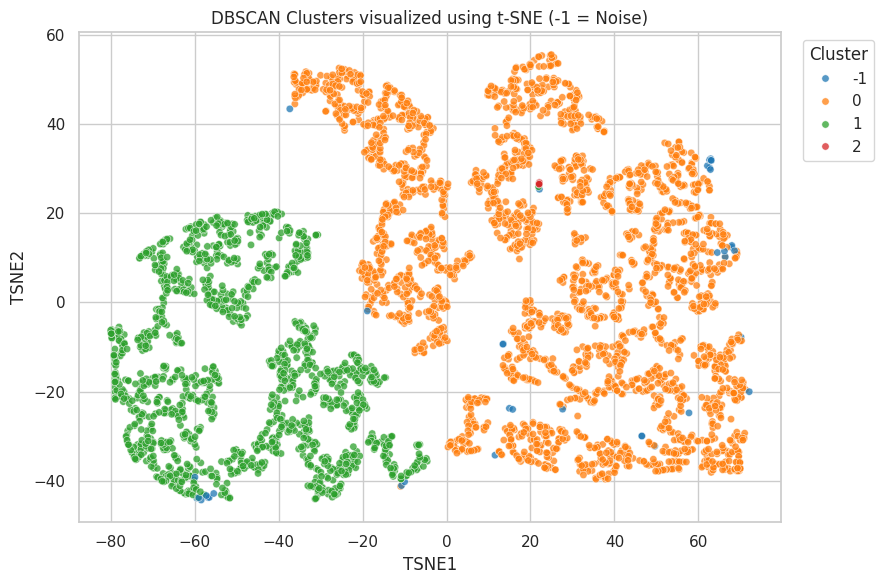

In [19]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=tsne_df["TSNE1"],
    y=tsne_df["TSNE2"],
    hue=rfm["DBSCAN_Cluster"].astype(str),
    palette="tab10",
    s=28,
    alpha=0.75
)
plt.title("DBSCAN Clusters visualized using t-SNE (-1 = Noise)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 17. Analyze K-Means customer segments
The profiles below use the original, untransformed RFM values so they are easier to interpret in business terms.

,Recency,Frequency,Monetary,Customer_Count
KMeans_Cluster,,,,
0,27.57,8.22,4442.64,1733
1,135.76,1.65,465.38,2605


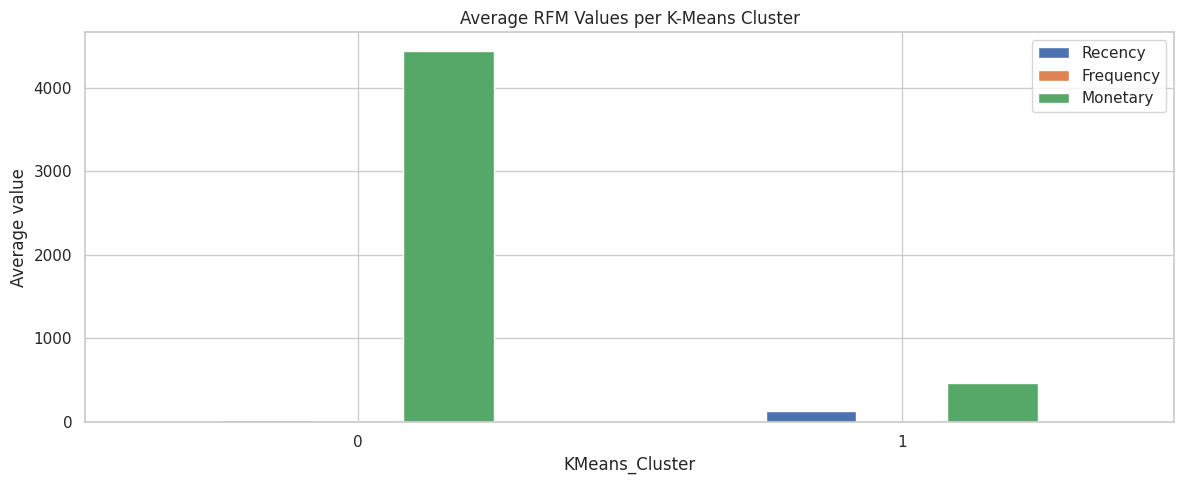

In [20]:
kmeans_profile = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

kmeans_sizes = rfm["KMeans_Cluster"].value_counts().sort_index().rename("Customer_Count")
kmeans_profile = kmeans_profile.join(kmeans_sizes)

display(kmeans_profile)

kmeans_profile[["Recency", "Frequency", "Monetary"]].plot(
    kind="bar",
    figsize=(12, 5)
)
plt.title("Average RFM Values per K-Means Cluster")
plt.ylabel("Average value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 18. Generate marketing personas and recommendations
Personas are assigned using relative comparisons with the overall median RFM values. They are heuristic interpretations, so review the actual cluster profiles before presenting them as business conclusions.

In [21]:
overall_medians = rfm[["Recency", "Frequency", "Monetary"]].median()

def create_persona(row, medians):
    recent = row["Recency"] <= medians["Recency"]
    frequent = row["Frequency"] >= medians["Frequency"]
    valuable = row["Monetary"] >= medians["Monetary"]

    if recent and frequent and valuable:
        return (
            "Champions",
            "Reward with VIP benefits, early access, exclusive launches and loyalty rewards."
        )
    elif frequent and valuable:
        return (
            "Loyal High-Value Customers",
            "Offer membership upgrades, personalized recommendations and premium rewards."
        )
    elif recent and not frequent:
        return (
            "New or Promising Customers",
            "Use welcome offers, second-purchase incentives and relevant product recommendations."
        )
    elif not recent and valuable:
        return (
            "At-Risk High-Spenders",
            "Run personalized win-back campaigns and offer relevant exclusive incentives."
        )
    elif not recent and not frequent:
        return (
            "Dormant or Low-Engagement Customers",
            "Test low-cost reactivation campaigns and suppress unresponsive contacts."
        )
    elif frequent:
        return (
            "Regular Customers",
            "Encourage repeat purchases with loyalty points, bundles and replenishment reminders."
        )
    else:
        return (
            "Occasional Customers",
            "Use targeted promotions and personalized product recommendations."
        )

persona_rows = []

for cluster_id, row in kmeans_profile.iterrows():
    persona, strategy = create_persona(row, overall_medians)
    persona_rows.append({
        "KMeans_Cluster": cluster_id,
        "Customer_Count": int(row["Customer_Count"]),
        "Persona": persona,
        "Average_Recency_Days": row["Recency"],
        "Average_Frequency": row["Frequency"],
        "Average_Monetary": row["Monetary"],
        "Marketing_Recommendation": strategy
    })

persona_df = pd.DataFrame(persona_rows)
display(persona_df)

,KMeans_Cluster,Customer_Count,Persona,Average_Recency_Days,Average_Frequency,Average_Monetary,Marketing_Recommendation
0,0,1733,Champions,27.57,8.22,4442.64,"Reward with VIP benefits, early access, exclus..."
1,1,2605,Dormant or Low-Engagement Customers,135.76,1.65,465.38,Test low-cost reactivation campaigns and suppr...


## 19. Analyze DBSCAN customer segments

In [22]:
dbscan_non_noise = rfm[rfm["DBSCAN_Cluster"] != -1]

if not dbscan_non_noise.empty:
    dbscan_profile = dbscan_non_noise.groupby("DBSCAN_Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ].mean().round(2)
    dbscan_profile["Customer_Count"] = dbscan_non_noise.groupby("DBSCAN_Cluster").size()
    display(dbscan_profile)
else:
    dbscan_profile = pd.DataFrame()
    print("DBSCAN did not assign any customers to a non-noise cluster.")

,Recency,Frequency,Monetary,Customer_Count
DBSCAN_Cluster,,,,
0,58.56,5.95,2778.28,2818
1,156.99,1.00,345.42,1478
2,103.00,1.00,4390.98,4


## 20. Compare K-Means and DBSCAN

In [23]:
comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Number_of_Clusters": int(rfm["KMeans_Cluster"].nunique()),
        "Silhouette_Score": kmeans_silhouette,
        "Davies_Bouldin_Index": kmeans_db,
        "Noise_Percentage": 0.0
    },
    {
        "Algorithm": "DBSCAN",
        "Number_of_Clusters": int(len(set(rfm["DBSCAN_Cluster"]) - {-1})),
        "Silhouette_Score": dbscan_silhouette,
        "Davies_Bouldin_Index": dbscan_db,
        "Noise_Percentage": float((rfm["DBSCAN_Cluster"] == -1).mean() * 100)
    }
])

display(comparison)

,Algorithm,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index,Noise_Percentage
0,K-Means,2,0.423668,0.891431,0.00000
1,DBSCAN,3,0.184913,0.966819,0.87598


## 21. Export results
The following CSV files contain customer-level cluster assignments and the K-Means persona summary.

In [24]:
final_results = rfm.copy()
final_results.to_csv("customer_segmentation_results.csv", index=True)
persona_df.to_csv("customer_personas.csv", index=False)
comparison.to_csv("clustering_comparison.csv", index=False)

print("Exported:")
print("- customer_segmentation_results.csv")
print("- customer_personas.csv")
print("- clustering_comparison.csv")

Exported:
- customer_segmentation_results.csv
- customer_personas.csv
- clustering_comparison.csv


## 22. Download output files from Google Colab

In [25]:
from google.colab import files

files.download("customer_segmentation_results.csv")
files.download("customer_personas.csv")
files.download("clustering_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 23. Conclusion template

After running the notebook, write your conclusion using your actual outputs:

1. The transaction dataset was cleaned and aggregated into customer-level Recency, Frequency and Monetary features.
2. K-Means divided customers into the selected number of clusters. The Elbow and Silhouette methods were used to guide the choice of K.
3. DBSCAN identified density-based customer groups and marked observations outside dense regions as noise.
4. PCA and t-SNE were used to visualize customer structure in two dimensions.
5. Cluster-level RFM profiles were interpreted as customer personas and linked to marketing recommendations.

**Reporting note:** Do not claim that one algorithm is better solely because of one score. Consider cluster separation, DBSCAN's noise percentage, segment sizes and whether the resulting groups are useful to the business.